# IS 4487 Assignment 6: Data Cleaning with Airbnb Listings

In this assignment, you will:
- Load a raw Airbnb listings dataset
- Identify and resolve missing or inconsistent data
- Decide what data to drop, keep, or clean
- Save a clean dataset to use in Assignment 7

## Why This Matters

Data cleaning is one of the most important steps in any analysis — but it's often the least visible. Airbnb hosts, managers, and policy teams rely on clean data to make decisions. This assignment gives you experience cleaning raw data and justifying your choices so others can understand your process.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_06_data_cleaning.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

📌 The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.


## 1. Choose a City & Upload Your Dataset

📥 Follow these steps:

1. Go to: [https://insideairbnb.com/get-the-data/](https://insideairbnb.com/get-the-data/)
2. Choose a city you’re interested in.
3. Download the file named: **`listings.csv.gz`** under that city.
4. In your notebook:
   - Open the left sidebar
   - Click the folder icon 📁
   - Click the upload icon ⬆️ and choose your `listings.csv.gz` file
5. Use the file path `/content/listings.csv.gz` when loading your data.
6. Import standard libraries (`pandas`, `numpy`, `seaborn`, `matplotlib`)


In [1]:
# Import necessary libraries 🔧
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Load your uploaded file (path "/content/listings.csv.gz") 🔧
df = pd.read_csv("/content/listings.csv.gz")
print(df.head())

        id                           listing_url       scrape_id last_scraped  \
0  2992450  https://www.airbnb.com/rooms/2992450  20260616211424   2026-06-16   
1  3820211  https://www.airbnb.com/rooms/3820211  20260616211424   2026-06-16   
2  5651579  https://www.airbnb.com/rooms/5651579  20260616211424   2026-06-16   
3  6623339  https://www.airbnb.com/rooms/6623339  20260616211424   2026-06-16   
4  9501054  https://www.airbnb.com/rooms/9501054  20260616211424   2026-06-16   

        source                                              name  \
0  city scrape                        Luxury 2 bedroom apartment   
1  city scrape         Restored Precinct in Center Sq. w/Parking   
2  city scrape        Large studio apt  by Capital Center & ESP@   
3  city scrape  Center Sq. Loft in Converted Precinct w/ Parking   
4  city scrape  Spacious suite with full bath by Capital  Center   

                                         description  neighborhood_overview  \
0  The apartment is locat

## 2. Explore Missing Values

### Business framing:

Stakeholders don’t like surprises in the data. Missing values can break dashboards, confuse pricing models, or create blind spots for host managers.

### Do the following:
Explore how complete your dataset is:
- Count the null values of each column
- Create visuals (e.g. heatmaps, boxplots, bar charts, etc) to help show what columns are missing values
- Keep in mind which column(s) are missing too much data, you will delete these in the next step

In [3]:
# Add code here 🔧
pd.set_option("display.max_rows", None)

null_counts = df.isnull().sum().sort_values(ascending=False)
null_pct = (null_counts / len(df) * 100).round(1)

missing_report = pd.DataFrame({"null_count": null_counts, "null_pct": null_pct})
missing_report = missing_report[missing_report["null_count"] > 0]

print("Total rows:", len(df))
print(missing_report)

Total rows: 490
                              null_count  null_pct
neighborhood_overview                490     100.0
host_since                           490     100.0
host_response_time                   490     100.0
host_thumbnail_url                   490     100.0
host_acceptance_rate                 490     100.0
host_response_rate                   490     100.0
host_verifications                   490     100.0
neighbourhood                        490     100.0
host_total_listings_count            490     100.0
host_neighbourhood                   490     100.0
calendar_updated                     490     100.0
instant_bookable                     490     100.0
license                              490     100.0
neighbourhood_group_cleansed         490     100.0
host_about                           230      46.9
host_location                        142      29.0
bedrooms                             112      22.9
review_scores_cleanliness             60      12.2
review_scores_a

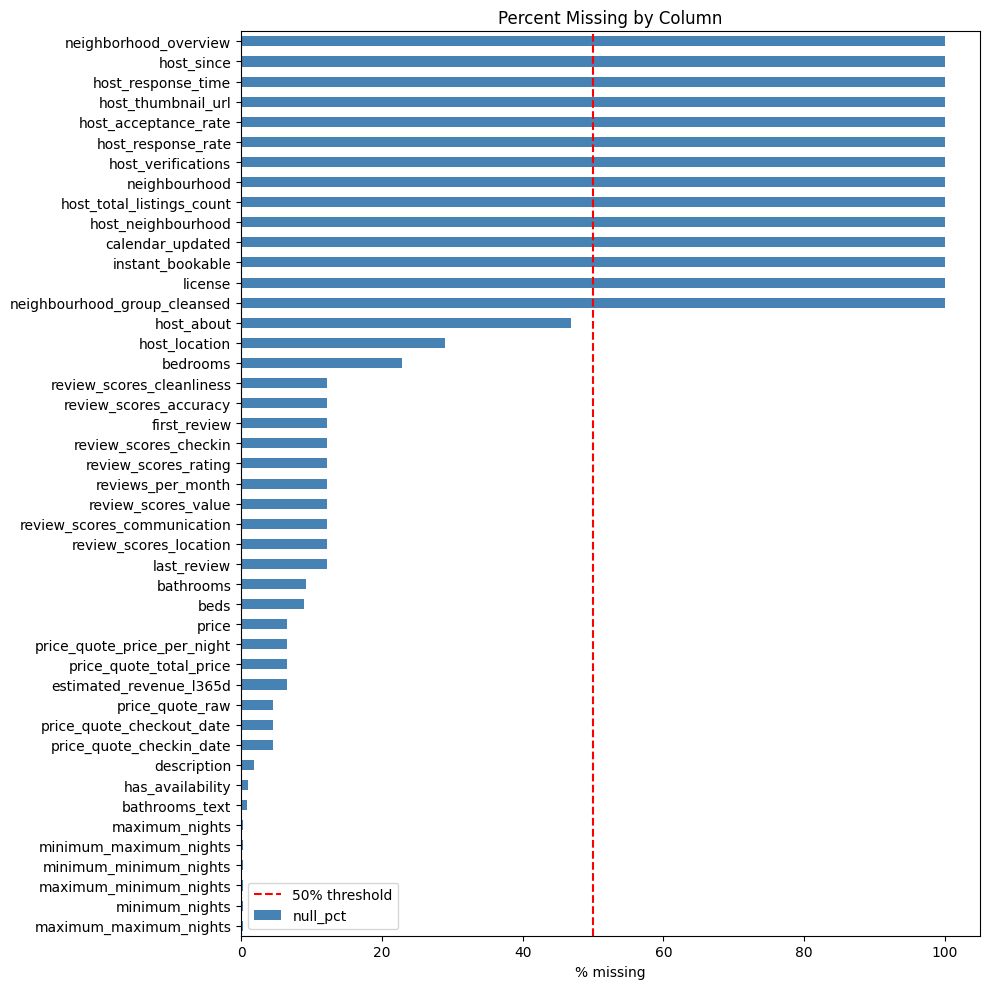

In [4]:
plt.figure(figsize=(10, 10))
missing_report["null_pct"].plot(kind="barh", color="steelblue")
plt.gca().invert_yaxis()
plt.axvline(50, color="red", linestyle="--", label="50% threshold")
plt.xlabel("% missing")
plt.title("Percent Missing by Column")
plt.legend()
plt.tight_layout()
plt.show()

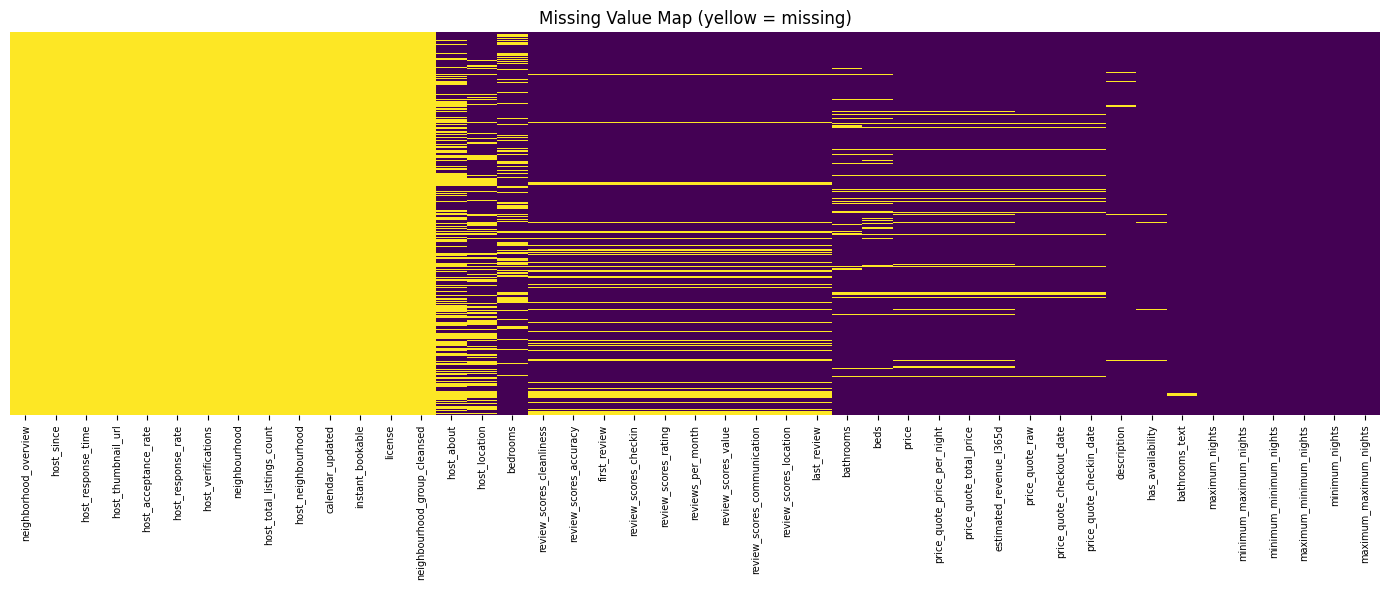

In [5]:
plt.figure(figsize=(14, 6))
sns.heatmap(df[missing_report.index].isnull().astype(int), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing Value Map (yellow = missing)")
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

### Reflection:
1. What are the top 3 columns with the most missing values?
2. Which ones are likely to create business issues?
3. Which could be safely ignored or dropped?

### ✍️ Your Response: 🔧
1. There are 14 columns missing 100% of their values. The first three that come up are neighborhood overview, host since, and host response time.

2. Price, bedrooms, and bathrooms are the most likely to cause problems. These attributes are the most impactful. Price is the core variable for most dashboards. Beds and baths generally drive the price one can charge for a listing.

3. The 14 empty columns can be dropped, they provide no value. Host about can be dropped as it's free text and provides little value as well. Host location can be dropped because it provides little value and has enough gaps.

## 3. Drop Columns That Aren’t Useful

### Business framing:  

Not every column adds value. Analysts often remove columns that are too empty, irrelevant, or repetitive — especially when preparing data for others.

### Do the following:
Make a decision:

- Choose 2–4 columns to drop from your dataset
- Document your reasons for each one
- Confirm they're gone with `.head()` or `.info()`

In [6]:
# Add code here 🔧
cols_to_drop = ["license", "calendar_updated", "host_thumbnail_url", "host_about"]

df = df.drop(columns=cols_to_drop)

print([c for c in cols_to_drop if c in df.columns])
print(df.shape)

[]
(490, 86)


### Reflection:
1. Which columns did you drop?
2. Why were they not useful from a business perspective?
3. What could go wrong if you left them in?

### ✍️ Your Response: 🔧
1. I dropped license, calendar updated, host thumbnail url, and host about.

2. The first three were completely empty, they had no information, so they provided no value. Host about was nearly half missing and is free text bios which don't support pricing, demand etc. It also would have been extremely difficult to transform that data into something usable.

3. Empty data columns create clutter and can break dashboards or models that may expect usable variables to be there. They make the dataset much harder to read and it gives a false impression on data coverage. Having a column would insinuate you have data for that, but we had nothing.



## 4. Fill or Fix Values in Key Columns

### Business framing:  

Let’s say your manager wants to see a map of listings with prices and review scores. If key fields are blank, the map won’t work. But not all missing values should be filled the same way.

### Do the following:
- Choose 2 columns with missing values
- Use a strategy to fill or flag those values
  - (e.g., median, “unknown”, forward-fill, or a placeholder)
- Explain what you did and why

In [7]:
# Your code for converting column data types 🔧
print("Missing bedrooms before:", df["bedrooms"].isnull().sum())
print("Median bedrooms:", df["bedrooms"].median())

df["bedrooms_was_missing"] = df["bedrooms"].isnull()
df["bedrooms"] = df["bedrooms"].fillna(df["bedrooms"].median())

print("Missing bedrooms after:", df["bedrooms"].isnull().sum())

Missing bedrooms before: 112
Median bedrooms: 1.0
Missing bedrooms after: 0


In [8]:
print("Missing ratings before:", df["review_scores_rating"].isnull().sum())

df["has_reviews"] = df["review_scores_rating"].notnull()

# Confirm the nulls line up with listings that have no reviews
print(df.groupby("has_reviews")["number_of_reviews"].describe()[["count", "max"]])

Missing ratings before: 60
             count    max
has_reviews              
False         60.0    0.0
True         430.0  996.0


### Reflection:
1. What two columns did you clean?
2. What method did you use for each, and why?
3. What risks are there in how you filled the data?

### ✍️ Your Response: 🔧
1. I cleaned the bedrooms and review scores rating columns.

2. For bedrooms I did a median fill method but added a new column to flag that bedrooms was missing for that listing and was filled with the median. Bedrooms is a skewed variable so median was a good option to keep larger houses from distorting the variable. For the reviews column I kept it but also added a new column with a boolean to flag that the listing had review. The reviews column was empty because the listings just didn't have any reviews yet.

3. The median filling I did with bedrooms assigns 1 bedroom to all unknown listings which could understate larger properties and skew price-to-bedroom analyses. It also shrinks the variation in the column. Leaving the ratings as is means the model must compute the 60 no-review listings. Also, dashboards need a no reviews category or those listings would always be filtered out.


## 5. Convert and Clean Data Types

### Business framing:  

Sometimes columns that look like numbers are actually stored as text — which breaks calculations and slows down analysis. Common examples are price columns with dollar signs or availability stored as strings.

### Do the following:
- Identify one column with the wrong data type
- Clean and convert it into a usable format (e.g., from string to number)
- Check your work by summarizing or plotting the cleaned column

float64
Missing prices: 32


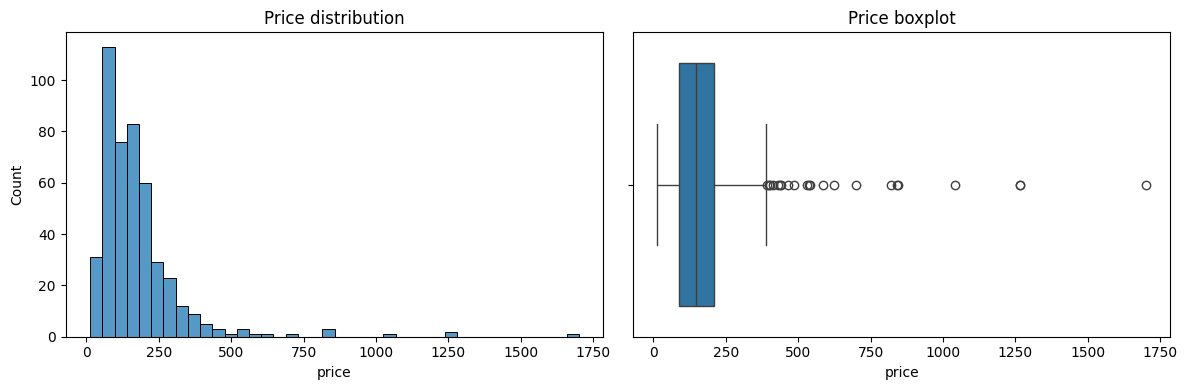

In [15]:
# Clean or adjust your dataset 🔧
df["price"] = (
    df["price"].astype(str)
    .str.replace(r"[$,]", "", regex=True)
    .replace("nan", np.nan)
    .astype(float)
)

print(df["price"].dtype)   # should be float64
print("Missing prices:", df["price"].isnull().sum())   # should still be 32

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price"].dropna(), bins=40, ax=ax[0])
ax[0].set_title("Price distribution")
sns.boxplot(x=df["price"], ax=ax[1])
ax[1].set_title("Price boxplot")
plt.tight_layout()
plt.show()

In [16]:
df["price"].describe()

,price
count,458.000000
mean,177.127293
std,157.348920
min,13.180000
25%,90.000000
50%,145.665000
75%,209.625000
max,1701.000000


### Reflection: :
1. What column did you fix?
2. What cleaning steps did you apply?
3. How does this help prepare the data for later use?

### ✍️ Your Response: 🔧
1. I fixed the price column.

2. Price was stored as text (object) because the values contained dollar signs and commas. I replaced the characters with a string replace function and then converted the column into a float64.

3. As a text, price would not be able to be averaged, sorted, compared, etc. A pricing map or dashboard would not work. As a number, it can now be used for summary statistics, comparisons, and pricing models. The plots also showed the high-priced outliers that may need to be reviewed.

## 6. Remove Duplicate Records

### Business framing:  

If a listing appears twice, it could inflate revenue estimates or confuse users. Airbnb needs each listing to be unique and accurate.

### Do the following:
- Check for rows that are exact duplicates
- If your data has an ID column and each ID is supposed to unique, then make sure there are no duplicate IDs
- Remove duplicates if found

In [17]:
# Add code here 🔧
print("Exact duplicate rows:", df.duplicated().sum())

print("Duplicate IDs:", df["id"].duplicated().sum())
print("Unique IDs:", df["id"].nunique(), "of", len(df), "rows")

Exact duplicate rows: 0
Duplicate IDs: 0
Unique IDs: 490 of 490 rows


### Reflection:
1. Did you find duplicates?
2. How did you decide what to drop or keep?
3. Why are duplicates risky for Airbnb teams?

### ✍️ Your Response: 🔧 🔧
1. I found no duplicates.

2. N/A

3. Duplicates can cause many different problems such as inflated totals, skewed averages, and misleading maps just to name a few. Each unique listing must only appear once.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 7**, where you'll perform data transformation techniques.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_6.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```





In [19]:
empty_cols = df.columns[df.isnull().all()].tolist()
print("Dropping", len(empty_cols), "empty columns:", empty_cols)
df = df.drop(columns=empty_cols)

for c in ["first_review", "last_review"]:
    df[c] = pd.to_datetime(df[c], errors="coerce")

print(df.shape)
print("Duplicate IDs:", df["id"].duplicated().sum())
df.info()

Dropping 0 empty columns: []
(490, 77)
Duplicate IDs: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 490 entries, 0 to 489
Data columns (total 77 columns):
 #   Column                                        Non-Null Count  Dtype         
---  ------                                        --------------  -----         
 0   id                                            490 non-null    int64         
 1   listing_url                                   490 non-null    object        
 2   scrape_id                                     490 non-null    int64         
 3   last_scraped                                  490 non-null    object        
 4   source                                        490 non-null    object        
 5   name                                          490 non-null    object        
 6   description                                   481 non-null    object        
 7   picture_url                                   490 non-null    object        
 8   host_id       

In [20]:
# export csv here 🔧
df.to_csv("cleaned_airbnb_data_6.csv", index=False)

## 8. Final Reflection

You’ve just cleaned a real-world Airbnb dataset — the kind of work that happens every day in analyst and data science roles.

Before you move on to data transformation in Assignment 7, take a few moments to reflect on the decisions you made and what you learned.

### Reflection:
1. Which section of the assignment was the most challenging for you? What made it challenging? Was it the coding or the application of class concepts?
2. Look back at your assignment and discuss a time when you had to drop, fix, or keep a piece of data. Why was it necessary to drop, fix, or keep that specific piece of data? (e.x. dropping a column full of null values because it has no useful information)
3. What’s one way a business team (e.g., hosts, pricing analysts, app administrators) might benefit from the cleaned version of this data?
4. If you had more time, what would you explore or clean further?
5. How does this relate to your customized learning outcome you created in canvas?


Write your response clearly in full sentences. No more than a few sentences required per response.


### ✍️ Your Response: 🔧

1. The parts requiring graphs or where graphs make it easier to interpret data are the hardest for me. I feel that graphs are extremely nuanced and require complex, complex to me at least, code to function in the way you want them to.
2. I had 14 columns that I completely dropped because they were entirely blank. They had no data and therefor provided no benefit to keep, they were only adding clutter and complexity.
3. A business team would benefit from my cleaned version of the data by having less dead space in the dataset that a model would have to process. The 14 empty columns would add process time and complexity that just isn't needed, especially the the model would be expecting values in those empty columns.
4. I actually did clean further. The initial time only let me clean 3 of 14 columns that were completely empty. Before I finished and exported, I deleted the remaining 11 empty columns to prepare for the next assignment.
5. This assignment mirrors what I imagine data prep work looks like for auditors before they complete testing. Checking for bad data (missing values, duplicates, etc.) is just another part of any due diligence process. Practicing in Python can test full populations instead of small samples while leaving a clear and repeatable trail for future reference and uses.


## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [12]:
!jupyter nbconvert --to html "assignment_06_data_cleaning.ipynb"

[NbConvertApp] WARNING | pattern 'assignment_06_data_cleaning.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=Tru